# Taak 6: MACE-dataset van CH4 in IRMOF-1

De data is gemaakt op de UGent HPC (joltik, V100) met `hpc/make_dataset.py` en de functies in `src/mace_dataset.py`:

- 4000 willekeurige posities uniform in de lege cel (seed 6), posities met baseline-energie > 10.000 K overgeslagen (CH4 op een roosteratoom).
- Per punt een all-atom CH4 met uniform willekeurige oriëntatie (quaternion) en het C-atoom exact op het punt.
- E_int = E(rooster + CH4) − E(rooster) − E(CH4 los) met MACE-MP-0 medium + D3 (float64), omgerekend naar K.
- Referenties: E(rooster) = −2834,1587 eV, E(CH4 los) = −23,9450 eV. Kost: ~0,3 s per punt.

Het CSV-bestand `data/mace_dataset_irmof1_ch4.csv` is meegecommit, zodat taak 7 zonder GPU draait.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.genfromtxt("../data/mace_dataset_irmof1_ch4.csv", delimiter=",", names=True)
E_base = data["E_baseline_K"]
E_mace = data["E_mace_K"]
K_TO_KJMOL = 1 / 120.27
print(len(data), "punten, kolommen:", data.dtype.names)
for name, E in (("baseline", E_base), ("MACE", E_mace)):
    print(f"{name:9s} [kJ/mol]: min {E.min() * K_TO_KJMOL:7.1f}  mediaan {np.median(E) * K_TO_KJMOL:7.1f}  max {E.max() * K_TO_KJMOL:8.1f}")

4000 punten, kolommen: ('x', 'y', 'z', 'qw', 'qx', 'qy', 'qz', 'E_baseline_K', 'E_mace_K')
baseline  [kJ/mol]: min   -13.9  mediaan    -4.0  max     83.1
MACE      [kJ/mol]: min   -29.9  mediaan    -4.0  max     82.9


## Check: histogram van E_MACE en vergelijking met de baseline

Verwachting uit TASKS.md: bulk rond −10 tot −20 kJ/mol (−1200 tot −2400 K), staart naar positief. Als baseline en MACE niet correleren klopt de plaatsing of de eenheid niet.

fractie E_MACE < 0: 0.91   (baseline: 0.82)
minimum E_MACE: -29.9 kJ/mol, minimum baseline: -13.9 kJ/mol
mediaan E_MACE (E<0): -4.6 kJ/mol, baseline (E<0): -4.7 kJ/mol
correlatie (E_baseline < 25 kJ/mol): 0.448


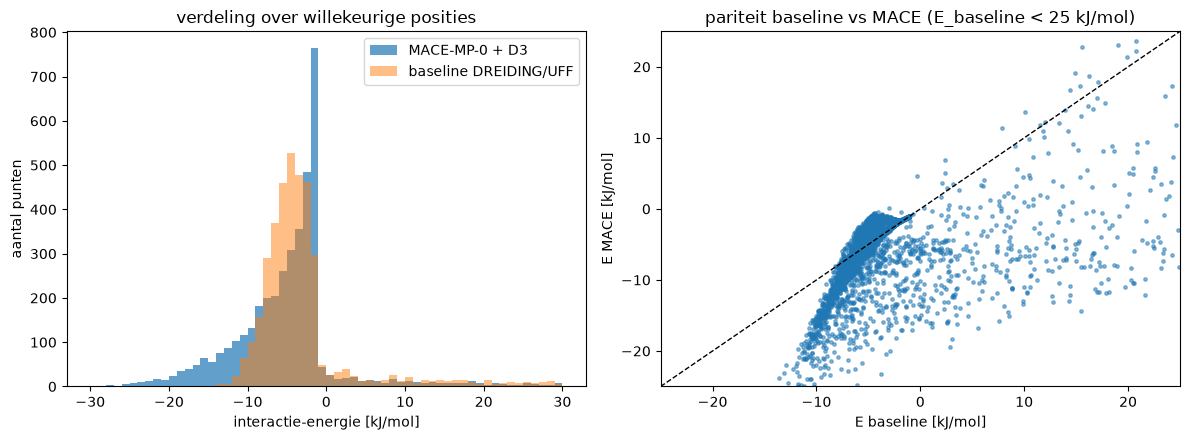

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(-30, 30, 61)
ax1.hist(E_mace * K_TO_KJMOL, bins=bins, alpha=0.7, label="MACE-MP-0 + D3")
ax1.hist(E_base * K_TO_KJMOL, bins=bins, alpha=0.5, label="baseline DREIDING/UFF")
ax1.set_xlabel("interactie-energie [kJ/mol]")
ax1.set_ylabel("aantal punten")
ax1.legend()
ax1.set_title("verdeling over willekeurige posities")

m = (E_base < 3000)
ax2.scatter(E_base[m] * K_TO_KJMOL, E_mace[m] * K_TO_KJMOL, s=6, alpha=0.5)
lim = [-25, 25]
ax2.plot(lim, lim, "k--", lw=1)
ax2.set_xlim(lim); ax2.set_ylim(lim)
ax2.set_xlabel("E baseline [kJ/mol]")
ax2.set_ylabel("E MACE [kJ/mol]")
ax2.set_title("pariteit baseline vs MACE (E_baseline < 25 kJ/mol)")
fig.tight_layout()
fig.savefig("../results/mace_dataset_overview.png", dpi=150)

neg = E_mace < 0
print(f"fractie E_MACE < 0: {neg.mean():.2f}   (baseline: {(E_base < 0).mean():.2f})")
print(f"minimum E_MACE: {E_mace.min() * K_TO_KJMOL:.1f} kJ/mol, minimum baseline: {E_base.min() * K_TO_KJMOL:.1f} kJ/mol")
print(f"mediaan E_MACE (E<0): {np.median(E_mace[neg]) * K_TO_KJMOL:.1f} kJ/mol, baseline (E<0): {np.median(E_base[E_base < 0]) * K_TO_KJMOL:.1f} kJ/mol")
print(f"correlatie (E_baseline < 25 kJ/mol): {np.corrcoef(E_base[m], E_mace[m])[0, 1]:.3f}")

## Widom met MACE rechtstreeks op de dataset

Omdat de posities uniform zijn, is ⟨exp(−E/T)⟩ over de dataset een Widom-schatting met MACE als krachtveld. De overgeslagen overlaps dragen exp(−E/T) ≈ 0 bij, dus die tellen mee in de noemer met nul in de teller. Dit geeft K_H(MACE) voor de tabel in taak 7.

In [3]:
import sys
sys.path.insert(0, "../src")
from energy import load_framework
from widom import rho_framework, henry_coefficient

positions, symbols, L, masses = load_framework("../data/IRMOF-1.cif")
rho_fw = rho_framework(masses, L)
T = 298.0
n_skipped = 3153  # uit de slurm-uitvoer van make_dataset.py
n_total = len(data) + n_skipped

def widom_from_dataset(E_K, n_total, T, n_blocks=10):
    b = np.exp(-np.asarray(E_K) / T)
    # overlaps als nullen toevoegen, dan blokken
    b = np.concatenate([b, np.zeros(n_total - len(b))])
    rng = np.random.default_rng(0)
    rng.shuffle(b)
    n = len(b) // n_blocks * n_blocks
    blocks = b[:n].reshape(n_blocks, -1).mean(axis=1)
    return blocks.mean(), blocks.std(ddof=1) / np.sqrt(n_blocks)

for name, col in (("baseline", E_base), ("MACE", E_mace)):
    bm, sem = widom_from_dataset(col, n_total, T)
    print(f"{name:9s}: <exp(-E/T)> = {bm:6.3f} +- {sem:.3f}   K_H = {henry_coefficient(bm, T, rho_fw):.3e} mol/kg/Pa")
print("ter vergelijking taak 3 (baseline, 100.000 inserties): <exp(-E/T)> = 5.634 +- 0.027, K_H = 3.83e-06")

baseline : <exp(-E/T)> =  5.731 +- 0.170   K_H = 3.899e-06 mol/kg/Pa
MACE     : <exp(-E/T)> = 211.947 +- 30.086   K_H = 1.442e-04 mol/kg/Pa
ter vergelijking taak 3 (baseline, 100.000 inserties): <exp(-E/T)> = 5.634 +- 0.027, K_H = 3.83e-06


/Users/kasperhuysentruyt/Documents/leven /Cusp/cusp-mlff-gcmc/.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


## Waar zit het verschil tussen MACE en baseline?

Twee vragen: (1) zijn de diepe MACE-putten (tot −30 kJ/mol) echte fysica of een artefact van H-atomen die in het rooster steken? (2) Wat domineert ⟨exp(−E/T)⟩?

In [4]:
from energy import distances_to_framework
from mace_dataset import rotation_matrix
from ase.build import molecule

symbols_arr = np.array(symbols)
order = np.argsort(E_mace)
print("10 diepste MACE-punten: E_mace, E_base [kJ/mol], afstand C tot dichtste roosteratoom, kleinste H-roosterafstand")
for i in order[:10]:
    pos = np.array([data["x"][i], data["y"][i], data["z"][i]])
    dist = distances_to_framework(positions, pos, L); j = dist.argmin()
    q = np.array([data["qw"][i], data["qx"][i], data["qy"][i], data["qz"][i]])
    ch4 = molecule("CH4"); rel = (ch4.get_positions() - ch4.get_positions()[0]) @ rotation_matrix(q).T
    dH = min(distances_to_framework(positions, h, L).min() for h in rel[1:] + pos)
    print(f"  {E_mace[i] * K_TO_KJMOL:6.1f} {E_base[i] * K_TO_KJMOL:6.1f}   C-min {dist[j]:.2f} A ({symbols_arr[j]})   H-min {dH:.2f} A")

print("\naandeel in <exp(-E_MACE/T)> per energieband:")
b = np.exp(-E_mace / T); tot = b.sum()
for lo, hi in ((-40, -20), (-20, -15), (-15, -10), (-10, -5), (-5, 0), (0, 100)):
    msk = (E_mace * K_TO_KJMOL >= lo) & (E_mace * K_TO_KJMOL < hi)
    print(f"  [{lo:4d}, {hi:4d}) kJ/mol: {msk.sum():5d} punten, aandeel {b[msk].sum() / tot:.3f}")

print("\nMACE - baseline als functie van de baseline-afstoting:")
for lo, hi in ((-2000, 0), (0, 1000), (1000, 3000), (3000, 6000), (6000, 10001)):
    msk = (E_base >= lo) & (E_base < hi)
    print(f"  E_base in [{lo:6d}, {hi:6d}) K: {msk.sum():5d} punten, mediaan(E_mace - E_base) = {np.median(E_mace[msk] - E_base[msk]) * K_TO_KJMOL:6.1f} kJ/mol")

10 diepste MACE-punten: E_mace, E_base [kJ/mol], afstand C tot dichtste roosteratoom, kleinste H-roosterafstand
   -29.9  -13.9   C-min 3.76 A (C)   H-min 2.90 A
   -27.7  -11.3   C-min 3.38 A (C)   H-min 2.76 A
   -27.6  -13.2   C-min 3.75 A (C)   H-min 3.05 A
   -27.3  -13.2   C-min 3.73 A (C)   H-min 2.97 A
   -27.2   -8.8   C-min 3.27 A (C)   H-min 2.62 A
   -26.3  -12.0   C-min 3.50 A (O)   H-min 2.87 A
   -26.0  -12.7   C-min 3.48 A (C)   H-min 2.90 A
   -25.9  -12.4   C-min 3.62 A (C)   H-min 2.86 A
   -25.3  -13.3   C-min 3.61 A (C)   H-min 2.71 A
   -25.1  -10.3   C-min 3.35 A (C)   H-min 2.54 A

aandeel in <exp(-E_MACE/T)> per energieband:
  [ -40,  -20) kJ/mol:    71 punten, aandeel 0.781
  [ -20,  -15) kJ/mol:   209 punten, aandeel 0.156
  [ -15,  -10) kJ/mol:   438 punten, aandeel 0.045
  [ -10,   -5) kJ/mol:   980 punten, aandeel 0.014
  [  -5,    0) kJ/mol:  1955 punten, aandeel 0.004
  [   0,  100) kJ/mol:   347 punten, aandeel 0.000

MACE - baseline als functie van de 

## Bevindingen

- **De diepe putten zijn geen artefact.** De tien diepste MACE-punten hebben het C-atoom 3,3 tot 3,8 Å van het dichtstbijzijnde roosteratoom (meestal een linker-C) en alle H-atomen minstens 2,5 Å van het rooster. Dat zijn normale fysisorptie-afstanden. MACE-MP-0 + D3 bindt CH4 aan de linkers tot −30 kJ/mol, de baseline tot −14 kJ/mol.
- **Waar baseline en MACE allebei aantrekkend zijn, komen ze goed overeen**: mediaan verschil 0,1 kJ/mol over 3291 punten. Het verschil zit in de staart naar diepe energieën (MACE) en in de afstotende wand: waar de baseline 6000 tot 10.000 K afstoting geeft, zit MACE nog op −10 kJ/mol. De LJ-wand van de baseline staat dus te ver naar buiten of is te steil. Dat is precies wat een vrije sigma in de student moet oplossen.
- **⟨exp(−E/T)⟩ wordt gedomineerd door 71 punten** met E < −20 kJ/mol (78% van de som). Daardoor is K_H(MACE) 37× groter dan K_H(baseline) en heeft hij een standaardfout van 15%. Experimenteel is Q_st ≈ 12 kJ/mol (Düren 2004 citeert 10,6 simulatie), dus MACE-MP-0 + D3 overschat de binding waarschijnlijk. Dat is de beperking "MACE-MP-0 + D3 is geen perfecte referentie" uit TASKS.md, nu met getallen. Voor de demo is dat niet erg: de vraag is of de student de leraar reproduceert, niet of de leraar gelijk heeft.
- Fractie posities met E < 0: 0,91 (MACE) tegenover 0,82 (baseline) binnen de niet-overgeslagen punten; 3153 van de 7153 willekeurige posities (44%) waren overlaps met baseline > 10.000 K.
- Kost op joltik (V100): 0,19 s per punt, 4000 punten in 12,5 minuten.

## Opmerkingen

- De dataset bevat voor elk punt ook de oriëntatie (quaternion), zodat later een all-atom analyse mogelijk is; de student (taak 7) gebruikt alleen x, y, z.
- De baseline-energie is de united-atom LJ op dezelfde positie, dus het paar (E_baseline, E_MACE) is direct de fout van het baseline-krachtveld per punt.